### the Allen Brain Observatory

personal project to study how different visual stimuli produce different patterns of neural activity in the mouse visual cortex.

In [1]:
import sys

print(sys.version)
print(sys.executable)

3.11.18 (main, Oct 25 2026, 19:41:29) [Clang 17.0.0 (clang-1700.6.4.2)]
/Users/aidanferguson-leighton/neural-decoding/neuroscience-env/bin/python


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

In [3]:
DATA_DIR = Path("data/allen_visual_coding")

DATA_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = DATA_DIR / "manifest.json"

print(manifest_path)

data/allen_visual_coding/manifest.json


In [4]:
import requests

url = "https://api.brain-map.org"

response = requests.get(url, timeout=15)

print(response.status_code)

200


In [5]:
import allensdk
import inspect

print("AllenSDK version:", allensdk.__version__)

print(
    "Cache constructor:",
    inspect.signature(EcephysProjectCache.from_warehouse)
)

AllenSDK version: 2.16.2
Cache constructor: (scheme: Optional[str] = None, host: Optional[str] = None, asynchronous: bool = False, manifest: Union[str, pathlib.Path, NoneType] = None, version: Optional[str] = None, cache: bool = True, fetch_tries: int = 2, timeout: int = 1200)


In [6]:
import time

start = time.time()

cache = EcephysProjectCache.from_warehouse(
    manifest=str(manifest_path),
    asynchronous=False,
    timeout=30,
    fetch_tries=1
)

print("Cache initialised!")
print(f"Time taken: {time.time() - start:.2f} seconds")

Cache initialised!
Time taken: 0.00 seconds


In [7]:
sessions = cache.fetch_api.get_sessions()

print("Number of sessions:", len(sessions))
print(sessions.head())

Number of sessions: 58
            date_of_acquisition  isi_experiment_id          published_at  \
id                                                                         
715093703  2019-01-19T08:54:18Z          705968051  2019-10-03T00:00:00Z   
719161530  2019-01-09T00:25:16Z          712195349  2019-10-03T00:00:00Z   
721123822  2019-01-09T00:25:35Z          715336286  2019-10-03T00:00:00Z   
732592105  2019-01-09T00:26:20Z          720112206  2019-10-03T00:00:00Z   
737581020  2018-09-25T21:03:59Z          724842748  2019-10-03T00:00:00Z   

           specimen_id           session_type  age_in_days sex  \
id                                                               
715093703    699733581  brain_observatory_1.1        118.0   M   
719161530    703279284  brain_observatory_1.1        122.0   M   
721123822    707296982  brain_observatory_1.1        125.0   M   
732592105    717038288  brain_observatory_1.1        100.0   M   
737581020    718643567  brain_observatory_1.1   

58 rows. Each row represents an experimental session.

## 3. Exploring experimental metadata

In [8]:
print("Rows:", sessions.shape[0])
print("Columns:", sessions.shape[1])
print("\nColumn names:")
print(sessions.columns.tolist())

Rows: 58
Columns: 9

Column names:
['date_of_acquisition', 'isi_experiment_id', 'published_at', 'specimen_id', 'session_type', 'age_in_days', 'sex', 'genotype', 'has_nwb']


In [9]:
print(sessions["session_type"].value_counts())

brain_observatory_1.1      32
functional_connectivity    26
Name: session_type, dtype: int64


In [10]:
print(sessions["sex"].value_counts())

print("\nAge statistics:")
print(sessions["age_in_days"].describe())

M    45
F    13
Name: sex, dtype: int64

Age statistics:
count     58.000000
mean     117.258621
std       12.910706
min       91.000000
25%      108.500000
50%      119.000000
75%      126.000000
max      142.000000
Name: age_in_days, dtype: float64


In [11]:
print(sessions["has_nwb"].value_counts())

True    58
Name: has_nwb, dtype: int64


In [12]:
print(sessions.isnull().sum())

date_of_acquisition    0
isi_experiment_id      0
published_at           0
specimen_id            0
session_type           0
age_in_days            0
sex                    0
genotype               0
has_nwb                0
dtype: int64


<Axes: >

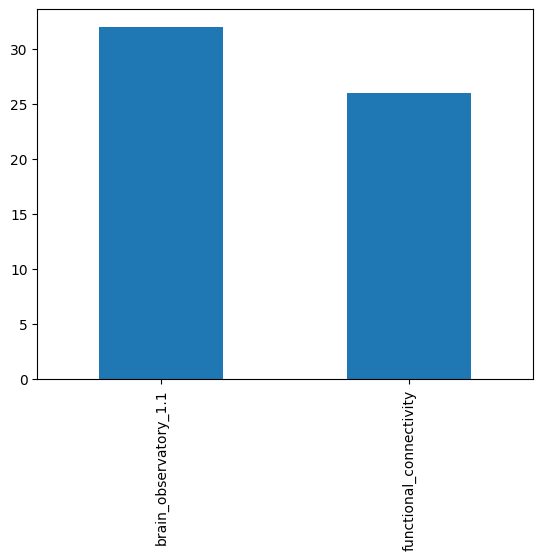

In [13]:
sessions["session_type"].value_counts().plot(kind="bar")

In [14]:
# getting available experimental sessions
sessions = cache.get_session_table()

# first few sessions
sessions.head()

,published_at,specimen_id,session_type,age_in_days,sex,full_genotype,unit_count,channel_count,probe_count,ecephys_structure_acronyms
id,,,,,,,,,,
715093703,2019-10-03T00:00:00Z,699733581,brain_observatory_1.1,118.0,M,Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,884,2219,6,"[CA1, VISrl, nan, PO, LP, LGd, CA3, DG, VISl, ..."
719161530,2019-10-03T00:00:00Z,703279284,brain_observatory_1.1,122.0,M,Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,755,2214,6,"[TH, Eth, APN, POL, LP, DG, CA1, VISpm, nan, N..."
721123822,2019-10-03T00:00:00Z,707296982,brain_observatory_1.1,125.0,M,Pvalb-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,444,2229,6,"[MB, SCig, PPT, NOT, DG, CA1, VISam, nan, LP, ..."
732592105,2019-10-03T00:00:00Z,717038288,brain_observatory_1.1,100.0,M,wt/wt,824,1847,5,"[grey, VISpm, nan, VISp, VISl, VISal, VISrl]"
737581020,2019-10-03T00:00:00Z,718643567,brain_observatory_1.1,108.0,M,wt/wt,568,2218,6,"[grey, VISmma, nan, VISpm, VISp, VISl, VISrl]"


In [15]:
# available columns
print(sessions.columns.tolist())

# num of units in each session
print(sessions["unit_count"].describe())

['published_at', 'specimen_id', 'session_type', 'age_in_days', 'sex', 'full_genotype', 'unit_count', 'channel_count', 'probe_count', 'ecephys_structure_acronyms']
count      58.000000
mean      689.827586
std       146.738595
min       415.000000
25%       571.500000
50%       690.000000
75%       818.500000
max      1005.000000
Name: unit_count, dtype: float64


415 and 1,005 recorded neural units per experimental session
* unit_count =	Number of identified neural units
* channel_count =	Number of recording channels
* probe_count =	Number of Neuropixels probes
* ecephys_structure_acronyms =	Brain regions sampled
* full_genotype =	Genetic characteristics of the mouse

The experiments sampled multiple brain regions, including visual cortex regions such as VISp, VISl and VISpm.

In [16]:
print(type(sessions["ecephys_structure_acronyms"].iloc[0]))
print(sessions["ecephys_structure_acronyms"].iloc[0])
print(sessions["ecephys_structure_acronyms"].head(5).tolist())

<class 'numpy.ndarray'>
['CA1' 'VISrl' nan 'PO' 'LP' 'LGd' 'CA3' 'DG' 'VISl' 'PoT' 'VISp' 'grey'
 'VISpm' 'APN' 'MB' 'VISam']
[array(['CA1', 'VISrl', nan, 'PO', 'LP', 'LGd', 'CA3', 'DG', 'VISl', 'PoT',
       'VISp', 'grey', 'VISpm', 'APN', 'MB', 'VISam'], dtype=object), array(['TH', 'Eth', 'APN', 'POL', 'LP', 'DG', 'CA1', 'VISpm', nan, 'NOT',
       'MB', 'SUB', 'VISp', 'VISam', 'grey', 'VL', 'CA3', 'CA2', 'VISl',
       'PO', 'VPM', 'LGd', 'VISal', 'VISrl'], dtype=object), array(['MB', 'SCig', 'PPT', 'NOT', 'DG', 'CA1', 'VISam', nan, 'LP', 'VIS',
       'ProS', 'VISp', 'LGv', 'CA3', 'VISl', 'APN', 'POL', 'LGd', 'HPF',
       'VISal', 'VISrl'], dtype=object), array(['grey', 'VISpm', nan, 'VISp', 'VISl', 'VISal', 'VISrl'],
      dtype=object), array(['grey', 'VISmma', nan, 'VISpm', 'VISp', 'VISl', 'VISrl'],
      dtype=object)]


In [17]:
visual_sessions = sessions[
    sessions["ecephys_structure_acronyms"].astype(str).str.contains(
        "VISp",
        na=False
    )
].sort_values("unit_count", ascending=False)

visual_sessions[
    ["unit_count", "probe_count", "ecephys_structure_acronyms"]
].head(10)

,unit_count,probe_count,ecephys_structure_acronyms
id,,,
794812542,1005,6,"[MB, APN, DG, CA1, VISrl, nan, PIL, MGm, MGv, ..."
757216464,959,6,"[LP, DG, CA3, CA1, VISrl, nan, PO, LGd, HPF, V..."
771160300,930,6,"[SCig, PPT, NOT, SUB, ProS, CA1, VISam, nan, A..."
750332458,902,6,"[grey, VISrl, nan, VISal, IntG, IGL, LGd, CA3,..."
742951821,893,6,"[VISal, nan, grey, VISl, VISrl, VISp, VISpm, VIS]"
715093703,884,6,"[CA1, VISrl, nan, PO, LP, LGd, CA3, DG, VISl, ..."
847657808,874,6,"[APN, NOT, DG, HPF, ProS, CA1, VISam, nan, MB,..."
779839471,863,6,"[APN, LP, MB, DG, CA1, VISrl, nan, TH, LGd, CA..."
751348571,859,6,"[grey, LGv, CA3, DG, CA1, VISl, nan, APN, POL,..."


In [18]:
# Find primary visual cortex (VISp) sessions
visual_sessions = sessions[
    sessions["ecephys_structure_acronyms"].apply(
        lambda regions: isinstance(regions, np.ndarray)
        and np.any(regions == "VISp")
    )
].sort_values("unit_count", ascending=False)

session_id = visual_sessions.index[0]

print("Selected session:", session_id)
print("Recorded units:", visual_sessions.iloc[0]["unit_count"])
print("Brain regions:", visual_sessions.iloc[0]["ecephys_structure_acronyms"])

Selected session: 794812542
Recorded units: 1005
Brain regions: ['MB' 'APN' 'DG' 'CA1' 'VISrl' nan 'PIL' 'MGm' 'MGv' 'MGd' 'CA3' 'VISal'
 'CA2' 'VISl' 'LP' 'POST' 'SUB' 'VISp' 'SCig' 'NOT' 'HPF' 'ProS' 'VISam'
 'POL' 'VISpm']


chose VISp as according to chatGPT "VISp refers to primary visual cortex. It's a particularly useful starting point because you're investigating how visual information is represented in the brain."

In [21]:
cache = EcephysProjectCache.from_warehouse(
    manifest=str(manifest_path),
    asynchronous=False,
    timeout=7200,
    fetch_tries=1
)

In [22]:
session = cache.get_session_data(794812542)

print("Units:", session.units.shape)
print("Probes:", session.probes.shape)

Downloading:   0%|          | 0.00/2.59G [00:00<?, ?B/s]

/Users/aidanferguson-leighton/neural-decoding/neuroscience-env/lib/python3.11/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.2.2, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)
/Users/aidanferguson-leighton/neural-decoding/neuroscience-env/lib/python3.11/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.2.2, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_names

Units: (1005, 40)
Probes: (6, 5)


In [23]:
print("Units:", session.units.shape)
print("\nUnit columns:")
print(session.units.columns.tolist())

print("\nStimulus presentations:")
print(session.stimulus_presentations.shape)
print(session.stimulus_presentations.head())

print("\nAvailable stimulus types:")
print(session.stimulus_presentations["stimulus_name"].value_counts())

Units: (1005, 40)

Unit columns:
['waveform_PT_ratio', 'waveform_amplitude', 'amplitude_cutoff', 'cluster_id', 'cumulative_drift', 'd_prime', 'firing_rate', 'isi_violations', 'isolation_distance', 'L_ratio', 'local_index', 'max_drift', 'nn_hit_rate', 'nn_miss_rate', 'peak_channel_id', 'presence_ratio', 'waveform_recovery_slope', 'waveform_repolarization_slope', 'silhouette_score', 'snr', 'waveform_spread', 'waveform_velocity_above', 'waveform_velocity_below', 'waveform_duration', 'filtering', 'probe_channel_number', 'probe_horizontal_position', 'probe_id', 'probe_vertical_position', 'structure_acronym', 'ecephys_structure_id', 'ecephys_structure_acronym', 'anterior_posterior_ccf_coordinate', 'dorsal_ventral_ccf_coordinate', 'left_right_ccf_coordinate', 'probe_description', 'location', 'probe_sampling_rate', 'probe_lfp_sampling_rate', 'probe_has_lfp_data']

Stimulus presentations:


/Users/aidanferguson-leighton/neural-decoding/neuroscience-env/lib/python3.11/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.2.2, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)


(77361, 19)
                         stimulus_block  start_time  stop_time Speed   Dir  \
stimulus_presentation_id                                                     
0                                  null    8.931548  68.998348  null  null   
1                                   0.0   68.998348  69.248554  null  null   
2                                   0.0   69.248554  69.498760  null  null   
3                                   0.0   69.498760  69.732286  null  null   
4                                   0.0   69.732286  69.982492  null  null   

                         x_position y_position stimulus_name  \
stimulus_presentation_id                                       
0                              null       null   spontaneous   
1                             -10.0       30.0        gabors   
2                             -20.0      -30.0        gabors   
3                              30.0      -10.0        gabors   
4                               0.0        0.0        gab